# Seleção ótima de ondas em uma sessão de surfe

**Projeto de Otimização (COS360)** — Luiz Felipe Píccoli Cavalini.

## 1. Introdução

### 1.1 O problema

Em uma sessão de surfe, o praticante decide, a cada onda que se aproxima, se rema para pegá-la ou
se a deixa passar. Embora pareça simples, essa decisão produz efeitos que se estendem ao longo da
sessão:

- As ondas chegam em **séries**, isto é, grupos de poucas ondas separados por intervalos de
  calmaria que podem durar minutos.
- Ao pegar uma onda, o surfista fica **indisponível** enquanto a percorre e enquanto rema de volta
  ao **pico**, ponto em que as ondas começam a quebrar e onde os surfistas aguardam. Quanto mais
  longa a onda, maior a distância percorrida e mais demorado o retorno.
- As ondas que chegam durante o retorno atingem o surfista e aumentam o tempo de retorno.
- O **fôlego** é limitado, e cada onda consome energia.

O tempo efetivamente surfado é pequeno. Em 60 sessões de 39 surfistas recreativos monitoradas por
GPS, 47,0% do tempo foi gasto remando, 41,6% esperando e apenas 8,1% em pé sobre as ondas [8].
Em competições, a proporção é semelhante: 54% do tempo remando e 8% surfando [9].

Surge, assim, um compromisso: a melhor onda de uma série pode impedir o aproveitamento da série
seguinte. Este trabalho formula a escolha das ondas como um problema de otimização, a partir da
seguinte pergunta: **em quais ondas o surfista deve remar para maximizar o tempo total em pé
durante a sessão?**

### 1.2 Breve histórico

O problema combina três ideias clássicas da pesquisa operacional.

**Programação linear e redes.** A programação linear foi sistematizada por Dantzig no fim da
década de 1940 [1]. Observou-se cedo que, em problemas de fluxo em redes, o método fornecia
soluções inteiras sem que essa condição fosse imposta. Hoffman e Kruskal explicaram o fenômeno em
1956: se a matriz de restrições é **totalmente unimodular** e o lado direito é inteiro, todos os
vértices do poliedro são inteiros [2]. Essa propriedade explica por que, na ausência das restrições
de fôlego, o problema estudado pode ser resolvido como um programa linear (Seção 2.5). Um
tratamento abrangente de fluxos em redes encontra-se em [3].

**Escalonamento de intervalos.** A seleção de um subconjunto de tarefas sem sobreposição no tempo,
cada uma com um valor associado, de modo a maximizar o valor total, constitui o problema do
*escalonamento ponderado de intervalos*, exemplo clássico de programação dinâmica [4]. Sem o tempo
de retorno e as ondas que atingem o surfista, a escolha de ondas se reduziria a esse problema.

**Caminho com restrição de recurso.** Quando se exige que um caminho em um grafo respeite um limite
de consumo de algum recurso (tempo, combustível, energia), o problema torna-se consideravelmente
mais difícil. Joksch estudou essa variante em 1966, por meio de programação dinâmica e de
programação inteira [5], e uma revisão abrangente do tema encontra-se em [6]. O problema central
deste trabalho, em que o fôlego é limitado e se recupera durante a espera, pertence a essa
classe: a energia funciona como um recurso consumido a cada onda e reposto entre elas. O método
*branch and bound*, proposto por Land e Doig em 1960 [7], é a base dos algoritmos empregados por
solvers como o Gurobi na resolução de programas inteiros.

### 1.3 Aplicações atuais

O caminho com restrição de recurso integra atualmente grandes sistemas de planejamento: trata-se
do subproblema resolvido repetidamente na roteirização de veículos e na elaboração de escalas de
tripulações aéreas por geração de colunas [6].

No esporte, a pesquisa operacional acumula pelo menos 50 anos de história, com aplicações em
tática e estratégia, elaboração de calendários de competição e previsão de resultados [10]. Os
estudos sobre surfe são, em sua maioria, de natureza fisiológica: quantificam o tempo dedicado a
cada atividade e o esforço envolvido [8, 9]. Em uma busca preliminar, não foram encontrados trabalhos que
tratem a escolha de ondas como problema de otimização.

### 1.4 Objetivos e organização

Este trabalho:

1. modela a sessão como um grafo em que cada caminho corresponde a uma sequência viável de ondas,
   e formula a escolha de ondas com fôlego limitado e recuperável como um **programa inteiro
   misto** (Seção 2);
2. resolve o modelo em um exemplo reduzido e em sessões de 40 ondas, comparando a solução ótima
   com regras simples que um surfista poderia adotar (Seção 3);
3. discute o papel das restrições de fôlego na dificuldade do problema, o efeito da formulação
   sobre o tempo de solução, a sensibilidade aos parâmetros estimados e as limitações do modelo
   (Seção 4).

## 2. Modelo matemático

### 2.1 Hipóteses

1. **Ondas conhecidas de antemão.** O modelo recebe a lista completa de ondas da sessão
   (modelo determinístico). Como, na prática, o surfista não conhece as ondas futuras, o ótimo do
   modelo constitui um **limite superior** para o desempenho de um surfista real.
2. **Um único surfista.** Não há disputa de ondas com outros praticantes.
3. **Ausência de canal.** Toda onda que chega durante a remada de retorno atinge o surfista.
4. **Tamanho medido pela duração.** A duração da onda, em segundos em pé, é adotada como medida
   de seu tamanho.
5. **Fôlego recuperável.** O surfista inicia a sessão com o fôlego máximo $U$. Cada onda consome
   uma quantidade fixa de energia, e a energia é recuperada à taxa $r$ apenas durante a espera no
   pico, sem ultrapassar $U$. Não há recuperação durante a remada de retorno.
6. **Consumo contabilizado na escolha.** O consumo $e_i$, que inclui a remada de retorno, é
   descontado integralmente no instante em que a onda é pega.

### 2.2 Dados de cada onda

| Símbolo | Significado | Unidade |
|---|---|---|
| $a_i$ | instante em que a onda $i$ chega ao pico | s |
| $v_i$ | valor da onda: segundos em pé que ela proporciona | s |
| $d_i$ | tempo durante o qual o surfista fica ocupado ao pegar a onda | s |
| $e_i$ | energia consumida para pegar a onda | s de remada |
| $U$ | fôlego máximo (energia no início da sessão e teto) | s de remada |
| $r$ | taxa de recuperação durante a espera no pico | s de remada por s |

Os dados de cada onda são $a_i$ e $v_i$; $d_i$ e $e_i$ são calculados. $U$ e $r$ são parâmetros
do surfista.

**Tempo ocupado.** Corresponde à soma de três parcelas:

$$d_i = \underbrace{v_i}_{\text{surfando}} + \underbrace{k \, v_i}_{\text{remada de volta}} + \underbrace{c \sum_{j \in H_i} v_j}_{\text{ondas na cabeça}}$$

- $k$: segundos de remada por segundo surfado. Como as distâncias de ida e de volta são iguais,
  $k$ equivale à razão entre a velocidade do surfista sobre a onda e a velocidade de remada.
  Estudos de tempo e movimento indicam a ordem de grandeza: a razão entre o tempo remando e o
  tempo surfando foi de aproximadamente 5,8 em surfistas recreativos [8] e de 6,75 em competição
  [9]. Como esse tempo de remada inclui também o posicionamento e a remada para entrar na onda,
  o retorno ao pico corresponde a apenas uma parte dele. Adota-se $k = 5$, e a Seção 4 avalia
  valores entre 3 e 8.
- $H_i$: conjunto das ondas que chegam enquanto o surfista rema de volta após a onda $i$.
- $c$: segundos perdidos por segundo de duração da onda que atinge o surfista.

$H_i$ **não é variável de decisão**: como as ondas são conhecidas, o conjunto é determinado antes
da montagem do modelo (pré-processamento). Cada onda que atinge o surfista prolonga a remada, que
pode então alcançar outras ondas; por isso, a contagem é repetida até que o conjunto se estabilize.

**Energia.** Medida em segundos de remada:

$$e_i = g_0 + (d_i - v_i)$$

em que $g_0$ representa o esforço da arrancada para entrar na onda, expresso em segundos de remada
equivalentes, e $d_i - v_i$ é o tempo de remada de retorno.

Os parâmetros $k$, $c$, $g_0$, $U$ e $r$ **não foram medidos diretamente**. Os valores adotados são
estimativas, e a Seção 4 examina a sensibilidade dos resultados a eles.

### 2.3 O grafo

A onda $j$ pode ser pega imediatamente após a onda $i$ somente se o surfista já tiver retornado
ao pico:

$$a_i + d_i \le a_j$$

Constrói-se um **grafo** (conjunto de nós ligados por arcos orientados) com um nó por onda, um nó
de início $s$ e um nó de fim $t$. O conjunto de arcos $A$ contém: $s \to i$ para toda onda,
$i \to j$ para todo par compatível, $i \to t$ para toda onda e $s \to t$. Cada caminho de $s$ a $t$
corresponde a uma sequência viável de ondas. O conflito de tempo, portanto, não aparece como
restrição: quando não há tempo para o retorno, o arco correspondente não existe.

### 2.4 O modelo

**Notação auxiliar.** Para cada arco $(i, j)$ entre duas ondas, o tempo de espera no pico é

$$w_{ij} = a_j - (a_i + d_i)$$

**Variáveis de decisão.**

- $y_{ij} \in \{0, 1\}$, para cada arco $(i, j) \in A$: vale 1 se, depois da onda $i$, a próxima onda
  pega é a $j$.
- $f_{ij} \ge 0$, para cada arco $(i, j)$ entre duas ondas: energia com que o surfista chega à onda
  $j$ vindo da onda $i$.

A energia com que o surfista chega à onda $i$ é, então, $u_i = U\,y_{si} + \sum_h f_{hi}$: o fôlego
máximo, se $i$ é a primeira onda, ou a energia trazida pelo arco de entrada.

**Objetivo.** Cada arco utilizado contribui com os segundos em pé da onda de destino ($v_t = 0$):

$$\max \sum_{(i,j) \in A} v_j \, y_{ij}$$

**Restrição 1: um único caminho.** Uma unidade de fluxo, que representa o surfista, sai de $s$, e
em cada onda o fluxo que entra é igual ao que sai:

$$\sum_{j} y_{sj} = 1, \qquad \sum_{i} y_{ik} = \sum_{j} y_{kj} \quad \forall k$$

**Restrição 2: energia apenas em arcos utilizados, limitada ao fôlego máximo.**

$$f_{ij} \le U\,y_{ij}$$

Se o arco não é utilizado, nenhuma energia o percorre; se é utilizado, a energia não excede $U$.

**Restrição 3: energia suficiente para pegar a onda.**

$$u_i \ge e_i \sum_h y_{hi} \quad \forall i$$

**Restrição 4: balanço de energia.** A energia que segue para a próxima onda não excede a energia
de chegada, descontado o consumo da onda e acrescida a recuperação durante a espera:

$$\sum_j f_{ij} \le u_i - e_i \sum_h y_{hi} + \sum_j r\,w_{ij}\,y_{ij} \quad \forall i$$

As restrições 2 a 4 funcionam como o balanço de um estoque em planejamento multiperíodo: a energia
é consumida a cada onda e reposta durante a espera.

Trata-se de um **programa inteiro misto**: as variáveis $y_{ij}$ são binárias e as variáveis
$f_{ij}$ são contínuas. O problema pertence à classe dos caminhos de maior valor com restrição de
recurso [5, 6].

### 2.5 Por que se trata de um programa inteiro

Sem as restrições de fôlego (2 a 4), a matriz de restrições é a de um problema de fluxo em redes,
que é **totalmente unimodular** (todo determinante de submatriz quadrada vale $-1$, $0$ ou $1$).
Com lado direito inteiro, todos os vértices do poliedro são inteiros [2], e um programa linear
forneceria $y \in \{0, 1\}$ mesmo com variáveis contínuas.

As restrições de fôlego eliminam essa propriedade. Na **relaxação linear** (o modelo com
$0 \le y_{ij} \le 1$), frações diferentes do surfista podem seguir caminhos distintos e compartilhar
a energia acumulada, o que produz soluções fracionárias sem interpretação física. Por essa razão,
as variáveis $y_{ij}$ precisam ser binárias, e o solver emprega *branch and bound* [7]. A Seção 3.4
ilustra esse comportamento no exemplo.

**Complexidade.** O problema é **NP-difícil**: não se conhece algoritmo que resolva qualquer
instância em tempo polinomial no número de ondas. Basta observar um caso particular. Se as ondas
forem suficientemente espaçadas para que qualquer combinação seja compatível no tempo, e se não
houver recuperação ($r = 0$), escolher as ondas equivale ao **problema da mochila**: os segundos em
pé $v_i$ são os valores, as energias $e_i$ são os pesos e o fôlego máximo $U$ é a capacidade. Um
algoritmo polinomial para o problema das ondas resolveria, portanto, a mochila em tempo polinomial.
No caso geral, com recuperação e tempos de espera, o problema é um caminho com restrição de recurso,
classe tratada como NP-difícil na literatura [5, 6]. Na prática, o *branch and bound* resolve as
instâncias deste trabalho em menos de um segundo, porque a relaxação da formulação adotada é
apertada (Seção 4.2).

## 3. Solução

### 3.1 Preparação

O solver utilizado é o **Gurobi**, acessado pela biblioteca `gurobipy`. A célula a seguir importa
as bibliotecas e cria um ambiente do solver sem mensagens de execução.

In [1]:
import random
import time
import copy
import gurobipy as gp
from gurobipy import GRB
import matplotlib.pyplot as plt

# Ambiente do Gurobi sem mensagens na tela
env = gp.Env(empty=True)
env.setParam('OutputFlag', 0)
env.start()

# Parâmetros estimados (ver Seção 4 para a sensibilidade)
K  = 5     # segundos de remada de volta por segundo surfado
C  = 0.5   # segundos perdidos por segundo de duração da onda que atinge o surfista
G0 = 20    # esforço da arrancada, em segundos de remada equivalentes

# Cores e estilo dos gráficos
AZUL, LARANJA, VERDE, CINZA = '#2a78d6', '#eb6834', '#1baf7a', '#b4b2a9'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e4dc', 'grid.linewidth': 0.6,
                     'axes.axisbelow': True, 'figure.dpi': 110, 'font.size': 10})

### 3.2 Pré-processamento

A função `prepara` calcula $d_i$, $H_i$ e $e_i$ para cada onda e retorna a lista de arcos do grafo.

In [2]:
def prepara(ondas, k=K, c=C, g0=G0):
    # Preenche d (tempo ocupado), H (ondas na cabeça) e e (energia) e devolve os arcos
    for i, o in ondas.items():
        fim_da_onda = o['a'] + o['v']          # instante em que termina de surfar
        atingem = []
        while True:
            fim_da_volta = fim_da_onda + k * o['v'] + c * sum(ondas[j]['v'] for j in atingem)
            novas = [j for j in ondas if fim_da_onda < ondas[j]['a'] < fim_da_volta]
            if novas == atingem:               # o conjunto parou de mudar
                break
            atingem = novas
        o['d'] = fim_da_volta - o['a']
        o['H'] = atingem
        o['e'] = g0 + (o['d'] - o['v'])

    compativeis = [(i, j) for i in ondas for j in ondas
                   if ondas[i]['a'] + ondas[i]['d'] <= ondas[j]['a']]
    return ([('s', i) for i in ondas] + compativeis
            + [(i, 't') for i in ondas] + [('s', 't')])

### 3.3 O modelo em código

A função `resolve` monta o programa inteiro misto da Seção 2.4. Com `relaxado=True`, as variáveis
$y_{ij}$ tornam-se contínuas no intervalo $[0, 1]$ (relaxação linear). Sem os argumentos `U` e `r`,
as restrições de fôlego são omitidas. O argumento `formulacao='bigM'` seleciona a formulação
alternativa discutida na Seção 4.2.

In [3]:
def resolve(ondas, arcos, U=None, r=None, relaxado=False, formulacao='fluxo'):
    m = gp.Model(env=env)
    tipo = GRB.CONTINUOUS if relaxado else GRB.BINARY
    y = m.addVars(arcos, lb=0, ub=1, vtype=tipo, name='y')

    # Objetivo: segundos em pé da onda de destino de cada arco utilizado
    valor = lambda no: ondas[no]['v'] if no in ondas else 0
    m.setObjective(gp.quicksum(valor(j) * y[i, j] for i, j in arcos), GRB.MAXIMIZE)

    # Restrição 1: um único caminho (conservação de fluxo)
    m.addConstr(y.sum('s', '*') == 1, name='saida_de_s')
    for k in ondas:
        m.addConstr(y.sum('*', k) == y.sum(k, '*'), name=f'conservacao_{k}')

    if U is not None:                                   # restrições de fôlego
        entre_ondas = [(i, j) for i, j in arcos if i in ondas and j in ondas]
        espera = {(i, j): ondas[j]['a'] - ondas[i]['a'] - ondas[i]['d'] for i, j in entre_ondas}

        if formulacao == 'fluxo':
            f = m.addVars(entre_ondas, lb=0, name='f')  # energia ao chegar em j vindo de i
            for i, j in entre_ondas:
                m.addConstr(f[i, j] <= U * y[i, j])     # restrição 2
            for i in ondas:
                chega = U * y['s', i] + f.sum('*', i)   # u_i: energia ao chegar em i
                gasto = ondas[i]['e'] * y.sum('*', i)
                recuperado = gp.quicksum(r * espera[a, j] * y[a, j] for a, j in entre_ondas if a == i)
                m.addConstr(chega >= gasto)                                  # restrição 3
                m.addConstr(f.sum(i, '*') <= chega - gasto + recuperado)     # restrição 4
        else:
            # Formulação big-M (Seção 4.2): uma variável de energia por onda
            M = U + max(o['e'] for o in ondas.values())
            u = m.addVars(list(ondas), lb=0, ub=U, name='u')
            for i, j in entre_ondas:
                m.addConstr(u[j] <= u[i] - ondas[i]['e'] + r * espera[i, j] + M * (1 - y[i, j]))
            for j in ondas:
                m.addConstr(u[j] >= ondas[j]['e'] * y.sum('*', j))

    m.optimize()
    return m, y


def caminho(y, arcos):
    # Reconstrói a sequência de ondas de uma solução inteira
    proximo = {i: j for (i, j) in arcos if y[i, j].X > 0.5}
    seq, no = [], 's'
    while no != 't':
        no = proximo[no]
        if no != 't':
            seq.append(no)
    return seq

### 3.4 Exemplo: 6 ondas, fôlego máximo 200 e recuperação 1

Considera-se um exemplo com duas séries de três ondas, com durações de 10, 20 e 30 segundos. O
surfista dispõe de fôlego máximo $U = 200$ e recupera $r = 1$ unidade de energia por segundo de
espera no pico.

In [4]:
exemplo = {
    1: dict(serie=1, a=0,   v=10),
    2: dict(serie=1, a=15,  v=20),
    3: dict(serie=1, a=30,  v=30),
    4: dict(serie=2, a=160, v=10),
    5: dict(serie=2, a=175, v=30),
    6: dict(serie=2, a=190, v=20),
}
arcos_ex = prepara(exemplo)

print(f"{'onda':>4} {'chega':>6} {'valor':>6} {'ocupado':>8} {'livre em':>9} {'energia':>8}  na cabeça")
for i, o in exemplo.items():
    print(f"{i:>4} {o['a']:>6} {o['v']:>6} {o['d']:>8.0f} {o['a'] + o['d']:>9.0f} {o['e']:>8.0f}  {o['H'] or '-'}")
print(len(arcos_ex), "arcos")

onda  chega  valor  ocupado  livre em  energia  na cabeça
   1      0     10       85        85       95  [2, 3]
   2     15     20      120       135      120  -
   3     30     30      210       240      200  [4, 5, 6]
   4    160     10       85       245       95  [5, 6]
   5    175     30      180       355      170  -
   6    190     20      120       310      120  -
19 arcos


In [5]:
def simula(ondas, regra, U=None, r=0):
    # Percorre as ondas em ordem de chegada aplicando uma regra simples
    melhor = {}
    for o in ondas.values():
        melhor[o['serie']] = max(melhor.get(o['serie'], 0), o['v'])
    livre_em, energia_livre, pegas = 0, (U if U is not None else float('inf')), []
    for i, o in ondas.items():
        if o['a'] < livre_em:
            continue                                     # ainda remando de volta
        energia = min(U, energia_livre + r * (o['a'] - livre_em)) if U is not None else energia_livre
        quer = True if regra == 'gulosa' else o['v'] == melhor[o['serie']]
        if quer and o['e'] <= energia:
            pegas.append(i)
            energia_livre = energia - o['e']
            livre_em = o['a'] + o['d']
    return pegas, sum(ondas[i]['v'] for i in pegas)

def compara(ondas, arcos, U=None, r=None):
    m, y = resolve(ondas, arcos, U=U, r=r)
    linhas = [('gulosa',) + simula(ondas, 'gulosa', U, r or 0),
              ('paciente',) + simula(ondas, 'paciente', U, r or 0),
              ('ótimo', caminho(y, arcos), m.ObjVal)]
    print(f"{'estratégia':<10} {'nº de ondas':>11} {'segundos em pé':>15}   ondas pegas")
    for nome, pegas, total in linhas:
        print(f"{nome:<10} {len(pegas):>11} {total:>15.0f}   {pegas}")
    return linhas

U_EX, R_EX = 200, 1
print(f"Fôlego máximo {U_EX}, recuperação {R_EX} por segundo de espera\n")
_ = compara(exemplo, arcos_ex, U=U_EX, r=R_EX)

Fôlego máximo 200, recuperação 1 por segundo de espera

estratégia nº de ondas  segundos em pé   ondas pegas
gulosa               2              20   [1, 4]
paciente             1              30   [3]
ótimo                2              40   [1, 5]


- A regra **gulosa** seleciona as ondas menores (1 e 4) e obtém 20 s.
- A regra **paciente** seleciona a maior onda da série 1 (onda 3), que consome todo o fôlego e cujo
  retorno se estende por toda a série 2; obtém 30 s.
- A solução **ótima** obtém 40 s. Há duas combinações com esse valor: ondas 1 e 5, e ondas 2 e 6.

**Por que as ondas 2 e 5 (50 s) não são viáveis.** Após a onda 2, restam $200 - 120 = 80$ unidades
de energia. O surfista retorna ao pico em 135 s e a onda 5 chega em 175 s: a espera de 40 s recupera
40 unidades, totalizando 120, inferior às 170 necessárias.

**Por que as ondas 1 e 5 são viáveis.** Após a onda 1, restam $200 - 95 = 105$ unidades. O retorno
ocorre em 85 s, e a espera de 90 s até a onda 5 recupera 90 unidades, totalizando 195, suficiente
para as 170 necessárias. Uma onda menor seguida de espera mais longa viabiliza a onda maior.

**Relaxação linear e efeito da recuperação.**

In [6]:
m_int, y_int = resolve(exemplo, arcos_ex, U=U_EX, r=R_EX)
m_rel, y_rel = resolve(exemplo, arcos_ex, U=U_EX, r=R_EX, relaxado=True)
print(f"Ótimo inteiro:    {m_int.ObjVal:.1f} s  ondas {caminho(y_int, arcos_ex)}")
print(f"Relaxação linear: {m_rel.ObjVal:.1f} s")
print("Arcos com valor positivo na relaxação:")
for a in arcos_ex:
    if y_rel[a].X > 1e-6:
        print(f"  {a}: {y_rel[a].X:.3f}")

m_sem_rec, y_sem_rec = resolve(exemplo, arcos_ex, U=U_EX, r=0)
print(f"\nSem recuperação (r = 0): {m_sem_rec.ObjVal:.0f} s  ondas {caminho(y_sem_rec, arcos_ex)}")

m_livre, y_livre = resolve(exemplo, arcos_ex, relaxado=True)
valores = sorted({round(y_livre[a].X, 6) for a in arcos_ex})
print(f"Sem restrições de fôlego, a relaxação dá {m_livre.ObjVal:.0f} s e as variáveis valem {valores}: já é inteira.")

Ótimo inteiro:    40.0 s  ondas [1, 5]
Relaxação linear: 43.3 s
Arcos com valor positivo na relaxação:
  ('s', 1): 0.667
  ('s', 2): 0.333
  (1, 5): 0.667
  (2, 5): 0.333
  (5, 't'): 1.000

Sem recuperação (r = 0): 30 s  ondas [3]
Sem restrições de fôlego, a relaxação dá 50 s e as variáveis valem [0.0, 1.0]: já é inteira.


Na relaxação, $\tfrac{2}{3}$ da unidade de fluxo percorre o caminho $s \to 1 \to 5 \to t$ (40 s) e
$\tfrac{1}{3}$ percorre $s \to 2 \to 5 \to t$ (50 s), resultando em $43{,}3$ s. Isoladamente, o
caminho pela onda 2 não dispõe de energia para a onda 5; na relaxação, porém, as duas frações
chegam à onda 5 e a energia é verificada em conjunto, de modo que a fração que descansou mais
compensa a que descansou menos. A solução é viável para o programa linear, mas não possui
interpretação física. Com $y \in \{0,1\}$, o ótimo é de 40 s, e a diferença $43{,}3 - 40$
corresponde ao **gap de integralidade**.

Dois contrastes completam o exemplo. Sem recuperação ($r = 0$), o ótimo cai para 30 s: a recuperação
durante a espera é o que viabiliza a combinação de duas ondas. Sem as restrições de fôlego, a
relaxação já fornece solução inteira, em conformidade com a unimodularidade total discutida na
Seção 2.5.

### 3.5 Sessões de 40 ondas

As instâncias são **sintéticas**, uma vez que não há base pública com o registro de ondas
individuais. O gerador utiliza uma semente fixa, que reproduz os mesmos valores a cada execução, e
poucos parâmetros com significado físico. As faixas adotadas são estimativas, e não medições.

| Parâmetro | Faixa |
|---|---|
| Calmaria entre séries | 180 a 300 s |
| Ondas por série | 3 a 5 |
| Intervalo entre ondas da mesma série | 10 a 14 s |
| Duração de cada onda | 8 a 30 s, com as mais longas no fim da série |

As sessões contêm 40 ondas para que os modelos, com cerca de 1.500 variáveis, respeitem o limite da licença que acompanha o
`gurobipy` (2.000 variáveis e 2.000 restrições). Com a licença acadêmica, o parâmetro `duracao`
pode ser aumentado.

In [7]:
def gera_sessao(duracao=2700, semente=7, calmaria=(180, 300)):
    rng = random.Random(semente)
    ondas, n, serie = {}, 0, 0
    t = rng.uniform(20, 60)                       # chegada da primeira série
    while t < duracao:
        serie += 1
        duracoes = sorted(rng.uniform(8, 30) for _ in range(rng.randint(3, 5)))
        if rng.random() < 0.5:                    # às vezes a maior é a penúltima
            duracoes[-1], duracoes[-2] = duracoes[-2], duracoes[-1]
        for v in duracoes:
            n += 1
            ondas[n] = dict(serie=serie, a=round(t), v=round(v))
            t += rng.uniform(10, 14)              # próxima onda da série
        t += rng.uniform(*calmaria)               # calmaria até a próxima série
    return ondas

espacado = gera_sessao()                                   # séries a cada 3 a 5 min
proximas = gera_sessao(duracao=1500, calmaria=(60, 150))   # séries a cada 1 a 2,5 min
assert [o['v'] for o in espacado.values()] == [o['v'] for o in proximas.values()]   # mesmas ondas
arcos_esp, arcos_prox = prepara(espacado), prepara(proximas)
for nome, s, a in (("Espaçado", espacado, arcos_esp), ("Séries próximas", proximas, arcos_prox)):
    print(f"{nome}: {len(s)} ondas, {max(o['serie'] for o in s.values())} séries, {len(a)} arcos")

Espaçado: 40 ondas, 11 séries, 805 arcos
Séries próximas: 40 ondas, 11 séries, 750 arcos


As duas sessões contêm as **mesmas 40 ondas**, com as mesmas durações, e diferem apenas na
calmaria entre as séries. Desse modo, as diferenças entre os resultados decorrem exclusivamente do
espaçamento das séries.

### 3.6 Resultados com fôlego máximo 400 e recuperação 0,5

Nas sessões, adota-se $U = 400$ e $r = 0{,}5$: o surfista recupera metade de um segundo de remada a
cada segundo de espera.

In [8]:
U_SESSAO, R_SESSAO = 400, 0.5
for nome, s, a in (("Mar espaçado", espacado, arcos_esp), ("Séries próximas", proximas, arcos_prox)):
    m_livre, _ = resolve(s, a)
    print(f"{nome}: sem restrições de fôlego, o ótimo seria {m_livre.ObjVal:.0f} s")
    linhas = compara(s, a, U=U_SESSAO, r=R_SESSAO)
    ganho = linhas[2][2] / linhas[1][2] - 1
    print(f"Ótimo sobre a regra paciente: +{100 * ganho:.0f}%\n")

Mar espaçado: sem restrições de fôlego, o ótimo seria 286 s


estratégia nº de ondas  segundos em pé   ondas pegas
gulosa              11             126   [1, 4, 8, 11, 16, 19, 22, 27, 31, 34, 38]
paciente             7             187   [2, 6, 9, 18, 26, 29, 36]
ótimo                8             206   [2, 6, 9, 20, 25, 32, 37, 39]
Ótimo sobre a regra paciente: +10%

Séries próximas: sem restrições de fôlego, o ótimo seria 186 s
estratégia nº de ondas  segundos em pé   ondas pegas
gulosa               7              81   [1, 4, 8, 11, 16, 23, 33]
paciente             4             105   [2, 9, 26, 39]
ótimo                7             122   [1, 7, 10, 21, 25, 33, 39]
Ótimo sobre a regra paciente: +16%



Como a solução ótima conhece todas as ondas da sessão e as regras simples decidem sem conhecer as
ondas futuras, a diferença entre elas representa o **ganho máximo possível** em relação às regras,
e não o ganho garantido de um surfista real. Parte dessa diferença decorre da melhor escolha das
ondas, e parte decorre da informação sobre o futuro; o modelo determinístico não separa as duas.

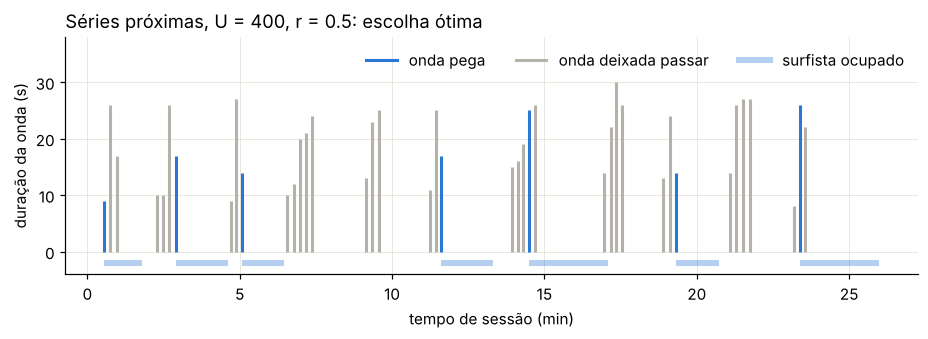

In [9]:
def desenha(ondas, pegas, titulo):
    fig, ax = plt.subplots(figsize=(10, 2.8))
    for i, o in ondas.items():
        cor = AZUL if i in pegas else CINZA
        ax.vlines(o['a'] / 60, 0, o['v'], color=cor, linewidth=2)
    for i in pegas:                               # faixa em que o surfista está ocupado
        o = ondas[i]
        ax.hlines(-2, o['a'] / 60, (o['a'] + o['d']) / 60, color=AZUL, linewidth=4, alpha=0.35)
    ax.plot([], [], color=AZUL, linewidth=2, label='onda pega')
    ax.plot([], [], color=CINZA, linewidth=2, label='onda deixada passar')
    ax.plot([], [], color=AZUL, linewidth=4, alpha=0.35, label='surfista ocupado')
    ax.set_xlabel('tempo de sessão (min)'); ax.set_ylabel('duração da onda (s)')
    ax.set_title(titulo, loc='left'); ax.legend(frameon=False, ncol=3, loc='upper right')
    ax.set_ylim(-4, 38)
    plt.show()

m, y = resolve(proximas, arcos_prox, U=U_SESSAO, r=R_SESSAO)
desenha(proximas, caminho(y, arcos_prox), f'Séries próximas, U = {U_SESSAO}, r = {R_SESSAO}: escolha ótima')

### 3.7 Efeito da taxa de recuperação

A comparação é repetida para diferentes taxas de recuperação $r$, com $U = 400$. Registra-se também
o valor da relaxação linear.

Mar espaçado
    r  gulosa  paciente  ótimo  relaxado
 0.25      98       151    151     152.6
  0.5     126       187    206     206.8
 0.75     126       237    243     245.1
  1.0     126       262    272     273.6
  1.5     126       286    286     286.0
  2.0     126       286    286     286.0



Séries próximas
    r  gulosa  paciente  ótimo  relaxado
 0.25      62        77     99     100.3
  0.5      81       105    122     123.7
 0.75      96       108    137     140.0
  1.0     104       135    146     151.7
  1.5     112       131    165     166.3
  2.0     126       154    170     174.9



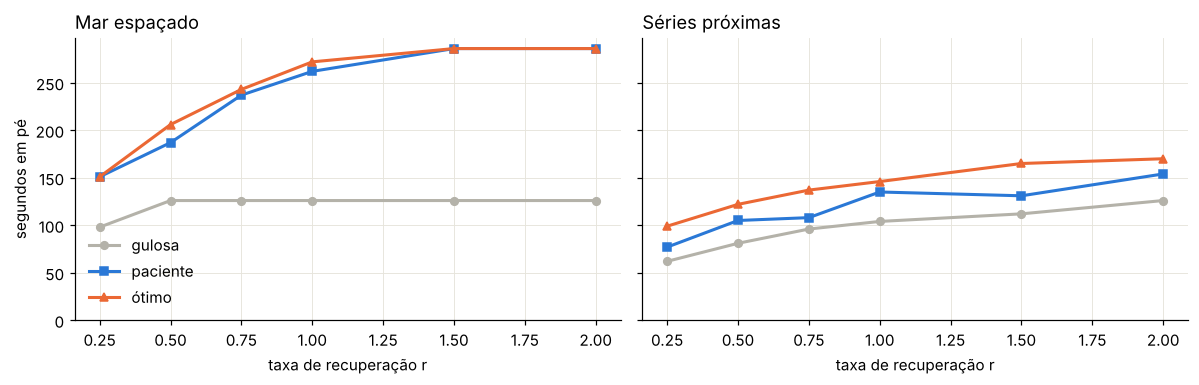

In [10]:
taxas = [0.25, 0.5, 0.75, 1.0, 1.5, 2.0]
resultados = {}
for nome, s, a in (("Mar espaçado", espacado, arcos_esp), ("Séries próximas", proximas, arcos_prox)):
    linhas = []
    for r in taxas:
        m, y = resolve(s, a, U=U_SESSAO, r=r)
        mr, _ = resolve(s, a, U=U_SESSAO, r=r, relaxado=True)
        linhas.append((r, simula(s, 'gulosa', U_SESSAO, r)[1], simula(s, 'paciente', U_SESSAO, r)[1], m.ObjVal, mr.ObjVal))
    resultados[nome] = linhas
    print(nome)
    print(f"{'r':>5} {'gulosa':>7} {'paciente':>9} {'ótimo':>6} {'relaxado':>9}")
    for r, g, p, o, rel in linhas:
        print(f"{r:>5} {g:>7.0f} {p:>9.0f} {o:>6.0f} {rel:>9.1f}")
    print()

fig, eixos = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, nome in zip(eixos, ("Mar espaçado", "Séries próximas")):
    L = resultados[nome]
    for idx, rot, cor, marca in ((1, 'gulosa', CINZA, 'o'), (2, 'paciente', AZUL, 's'), (3, 'ótimo', LARANJA, '^')):
        ax.plot([l[0] for l in L], [l[idx] for l in L], color=cor, linewidth=2, marker=marca, markersize=5, label=rot)
    ax.set_title(nome, loc='left'); ax.set_xlabel('taxa de recuperação r')
eixos[0].set_ylabel('segundos em pé'); eixos[0].set_ylim(bottom=0); eixos[0].legend(frameon=False)
plt.tight_layout(); plt.show()

A solução ótima nunca é inferior às regras simples. No mar espaçado, a regra paciente alcança o
ótimo nos extremos: com $r = 0{,}25$, o fôlego é tão escasso que ambas pegam as mesmas ondas, e a
partir de $r = 1{,}5$ o fôlego deixa de limitar o surfista. Nas taxas intermediárias, a regra fica
abaixo do ótimo.
Com séries próximas, a vantagem do ótimo permanece em todas as taxas: o intervalo curto entre as
séries limita a recuperação, e a escolha das ondas passa a depender do tempo de espera disponível
antes de cada uma.

## 4. Discussão

### 4.1 O papel das restrições de fôlego

Na ausência das restrições de fôlego, a relaxação linear já é inteira, e um programa linear é
suficiente (Seções 2.5 e 3.4). Com elas, o custo de uma onda passa a depender do histórico da
sessão, isto é, de quanto o surfista descansou antes dela, e a relaxação passa a admitir
combinações fracionárias de caminhos. Trata-se da mesma fronteira que separa o problema do caminho
mais curto do problema do caminho mais curto com restrição de recurso [5, 6].

### 4.2 Duas formulações para o mesmo problema

O balanço de energia admite uma formulação alternativa, com uma variável $u_j$ por onda e restrições
do tipo **big-M**, em que uma constante grande $M$ desativa a restrição quando o arco não é
utilizado:

$$u_j \le u_i - e_i + r\,w_{ij} + M(1 - y_{ij}), \qquad e_j \sum_i y_{ij} \le u_j \le U$$

As duas formulações descrevem o mesmo conjunto de soluções inteiras, mas diferem na relaxação
linear.

In [11]:
print(f"Mar espaçado, U = {U_SESSAO}, r = {R_SESSAO}")
print(f"{'formulação':<10} {'segundos em pé':>15} {'relaxação':>10} {'tempo (s)':>10}")
for nome in ('fluxo', 'bigM'):
    t0 = time.time()
    m, y = resolve(espacado, arcos_esp, U=U_SESSAO, r=R_SESSAO, formulacao=nome)
    tempo = time.time() - t0
    mr, _ = resolve(espacado, arcos_esp, U=U_SESSAO, r=R_SESSAO, formulacao=nome, relaxado=True)
    print(f"{nome:<10} {m.ObjVal:>15.0f} {mr.ObjVal:>10.1f} {tempo:>10.2f}")

Mar espaçado, U = 400, r = 0.5
formulação  segundos em pé  relaxação  tempo (s)


fluxo                  206      206.8       0.32


bigM                   206      285.3      11.38


As duas formulações atingem o mesmo ótimo, o que constitui uma verificação cruzada da
implementação. A relaxação da formulação big-M, entretanto, é muito mais fraca: com $y_{ij}$
fracionário, o termo $M(1 - y_{ij})$ praticamente desativa a restrição. O *branch and bound* precisa
então explorar um número muito maior de nós, e o tempo de solução aumenta. A formulação por arco é
a adotada no restante do trabalho.

### 4.3 Sensibilidade aos parâmetros estimados

Os parâmetros $k$ e $c$ não foram medidos diretamente. O modelo é resolvido com $U = 400$ e
$r = 0{,}5$ para uma grade de valores, nas duas sessões.

In [12]:
ks, cs = [3, 4, 5, 6, 7, 8], [0.0, 0.5, 1.0]

def grade_de_sensibilidade(**mar):
    grade = {}
    for c in cs:
        for k in ks:
            ondas = gera_sessao(**mar)
            a = prepara(ondas, k=k, c=c)
            m, y = resolve(ondas, a, U=U_SESSAO, r=R_SESSAO)
            grade[k, c] = (m.ObjVal, simula(ondas, 'paciente', U_SESSAO, R_SESSAO)[1])
    return grade

def imprime(grade, titulo):
    print(titulo, "(ótimo / paciente, em segundos em pé)")
    print(f"{'k':>3} " + " ".join(f"{'c=' + str(c):>13}" for c in cs))
    for k in ks:
        print(f"{k:>3} " + " ".join(f"{grade[k, c][0]:>6.0f} / {grade[k, c][1]:>4.0f}" for c in cs))
    print()

imprime(grade_de_sensibilidade(), "Mar espaçado")
imprime(grade_de_sensibilidade(duracao=1500, calmaria=(60, 150)), "Séries próximas")

Mar espaçado (ótimo / paciente, em segundos em pé)
  k         c=0.0         c=0.5         c=1.0
  3    296 /  286    286 /  286    286 /  286
  4    245 /  234    245 /  234    245 /  234
  5    206 /  187    206 /  187    206 /  187
  6    177 /  158    177 /  158    177 /  158
  7    155 /  153    154 /  153    154 /  153
  8    138 /  134    136 /  131    136 /  125



Séries próximas (ótimo / paciente, em segundos em pé)
  k         c=0.0         c=0.5         c=1.0
  3    195 /  185    191 /  184    191 /  128
  4    157 /  132    149 /  108    143 /  106
  5    132 /  108    122 /  105    115 /   74
  6    112 /  105    102 /   80     93 /   78
  7    100 /   83     91 /   74     82 /   50
  8     89 /   74     79 /   77     72 /   50



Em toda a grade, a solução ótima é igual ou superior à regra paciente, como esperado. A magnitude
da vantagem, contudo, varia com $k$ e $c$; por isso, os percentuais da Seção 3.6 devem ser
interpretados como ilustrativos, e não como medições.

### 4.4 Número de ondas ou tempo em pé

A formulação inicial do problema visava maximizar o **número** de ondas. Essa variante é obtida
fazendo-se $v_i = 1$ no objetivo, mantidos o tempo ocupado e a energia calculados a partir da
duração real de cada onda.

In [13]:
def compara_objetivos(ondas):
    arcos_o = prepara(ondas)
    m, y = resolve(ondas, arcos_o, U=U_SESSAO, r=R_SESSAO)
    por_segundos = caminho(y, arcos_o)
    contagem = copy.deepcopy(ondas)
    for o in contagem.values():
        o['v'] = 1
    m, y = resolve(contagem, arcos_o, U=U_SESSAO, r=R_SESSAO)
    por_contagem = caminho(y, arcos_o)
    for nome, pegas in (('segundos em pé', por_segundos), ('número de ondas', por_contagem)):
        total = sum(ondas[i]['v'] for i in pegas)
        print(f"  {nome:<16} {len(pegas):>3} ondas  {total:>4} s em pé  {total / len(pegas):>5.1f} s por onda")

print("Mar espaçado"); compara_objetivos(gera_sessao())
print("Séries próximas"); compara_objetivos(gera_sessao(duracao=1500, calmaria=(60, 150)))

Mar espaçado


  segundos em pé     8 ondas   206 s em pé   25.8 s por onda
  número de ondas   11 ondas   161 s em pé   14.6 s por onda
Séries próximas
  segundos em pé     7 ondas   122 s em pé   17.4 s por onda
  número de ondas    8 ondas    89 s em pé   11.1 s por onda


Ao maximizar o número de ondas, o modelo passa a privilegiar ondas **curtas**, que consomem menos
fôlego e permitem retorno mais rápido ao pico. O número de ondas aumenta, mas o tempo em pé
diminui. Por essa razão, adota-se o tempo em pé como objetivo principal.

### 4.5 Limitações

- **Ondas conhecidas de antemão.** Trata-se da hipótese mais restritiva. O ótimo constitui um
  **limite superior**, e a diferença entre ele e as regras simples mede o valor da informação
  sobre as ondas futuras.
- **Um único surfista.** Em picos movimentados, a disputa por ondas com outros surfistas tende a
  ser o fator dominante. Uma generalização substituiria $v_j$ pelo valor esperado $p_j v_j$, em que
  $p_j$ é a probabilidade de a onda ser aproveitada pelo surfista.
- **Parâmetros estimados.** O fator $k$ apoia-se em medições publicadas [8, 9]; $c$, $g_0$, $U$, $r$
  e as faixas do gerador são estimativas.
- **Recuperação simplificada.** A recuperação é linear no tempo de espera e não ocorre durante a
  remada de retorno; na prática, ela tende a desacelerar à medida que o surfista se aproxima do
  fôlego máximo.
- **Duração como medida de valor.** Uma onda longa e de baixa qualidade vale mais do que uma onda
  curta e de boa qualidade.

## Referências

[1] DANTZIG, G. B. *Linear Programming and Extensions*. Princeton: Princeton University Press, 1963.

[2] HOFFMAN, A. J.; KRUSKAL, J. B. Integral boundary points of convex polyhedra. In: KUHN, H. W.;
TUCKER, A. W. (eds.). *Linear Inequalities and Related Systems*. Annals of Mathematics Studies 38.
Princeton: Princeton University Press, 1956. Reimpresso em: JÜNGER, M. et al. (eds.).
*50 Years of Integer Programming 1958-2008*. Berlin: Springer, 2010. doi:10.1007/978-3-540-68279-0_3.

[3] AHUJA, R. K.; MAGNANTI, T. L.; ORLIN, J. B. *Network Flows: Theory, Algorithms, and
Applications*. Englewood Cliffs: Prentice Hall, 1993.

[4] KLEINBERG, J.; TARDOS, É. *Algorithm Design*. Boston: Pearson/Addison-Wesley, 2005. Cap. 6.

[5] JOKSCH, H. C. The shortest route problem with constraints. *Journal of Mathematical Analysis
and Applications*, v. 14, n. 2, p. 191-197, 1966. doi:10.1016/0022-247X(66)90020-5.

[6] IRNICH, S.; DESAULNIERS, G. Shortest path problems with resource constraints. In:
DESAULNIERS, G.; DESROSIERS, J.; SOLOMON, M. M. (eds.). *Column Generation*. New York: Springer,
2005. p. 33-65. doi:10.1007/0-387-25486-2_2.

[7] LAND, A. H.; DOIG, A. G. An automatic method of solving discrete programming problems.
*Econometrica*, v. 28, n. 3, p. 497-520, 1960.

[8] BARLOW, M. J. et al. The effect of wave conditions and surfer ability on performance and the
physiological response of recreational surfers. *Journal of Strength and Conditioning Research*,
v. 28, n. 10, p. 2946-2953, 2014. doi:10.1519/JSC.0000000000000491.

[9] FARLEY, O. R. L.; HARRIS, N. K.; KILDING, A. E. Physiological demands of competitive surfing.
*Journal of Strength and Conditioning Research*, v. 26, n. 7, p. 1887-1896, 2012.
doi:10.1519/JSC.0b013e3182392c4b.

[10] WRIGHT, M. B. 50 years of OR in sport. *Journal of the Operational Research Society*,
v. 60, p. S161-S168, 2009. doi:10.1057/jors.2008.170.